# Thu Thập và Khám Phá Dữ Liệu Bệnh Trên Lá Lúa (Collection & EDA)

Notebook này thực hiện các nội dung chính:
1. Khám phá tập dữ liệu thô (**data_raw**) tải về từ Kaggle: kiểm tra cấu trúc 4 lớp bệnh gốc, số lượng mẫu, dung lượng lưu trữ và hiển thị ảnh mẫu.
2. Khám phá tập dữ liệu đã qua tiền xử lý (**data_processed**): dữ liệu được chuẩn hóa, gắn nhãn thông qua Roboflow và tự động phân chia sẵn thành các tập `train`, `valid`, `test` kèm theo tệp chú thích `labels.csv`.
3. So sánh trực quan sự khác biệt giữa dữ liệu thô và dữ liệu đã xử lý về số lượng mẫu, dung lượng và cấu trúc tổ chức.

In [10]:
import os
import glob
import random
import warnings
from pathlib import Path
from PIL import Image
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True
%matplotlib inline

# Xác định thư mục dự án và thư mục dataset
possible_roots = [
    Path('../dataset').resolve(),
    Path('dataset').resolve(),
    Path('./dataset').resolve()
]
DATASET_DIR = None
for p in possible_roots:
    if p.exists() and p.is_dir():
        DATASET_DIR = p
        break

RAW_DIR = DATASET_DIR / 'data_raw'
PROCESSED_DIR = DATASET_DIR / 'data_processed'

print(f"Thư mục gốc dữ liệu : {DATASET_DIR}")
print(f"Thư mục data_raw    : {RAW_DIR} ({'Tồn tại' if RAW_DIR.exists() else 'Không tồn tại'})")
print(f"Thư mục data_processed: {PROCESSED_DIR} ({'Tồn tại' if PROCESSED_DIR.exists() else 'Không tồn tại'})")

Thư mục gốc dữ liệu : C:\Users\Nguyen Thanh Huy\Documents\Machine_Learning\CNN_Predict_\dataset
Thư mục data_raw    : C:\Users\Nguyen Thanh Huy\Documents\Machine_Learning\CNN_Predict_\dataset\data_raw (Tồn tại)
Thư mục data_processed: C:\Users\Nguyen Thanh Huy\Documents\Machine_Learning\CNN_Predict_\dataset\data_processed (Tồn tại)


---
## 1. Khám Phá Dữ Liệu Thô (data_raw)

- **Nguồn gốc dữ liệu**: [Kaggle - Rice Disease Dataset](https://www.kaggle.com/datasets/anshulm257/rice-disease-dataset) (Tác giả: `anshulm257`).
- **Cấu trúc tổ chức**: Gồm 4 thư mục tương ứng với 4 lớp bệnh gốc bằng tiếng Anh:
  - `Bacterial Leaf Blight`: Bệnh bạc lá lúa (do vi khuẩn *Xanthomonas oryzae* gây ra).
  - `Brown Spot`: Bệnh đốm nâu (do nấm *Bipolaris oryzae* gây ra).
  - `Healthy Rice Leaf`: Lá lúa khỏe mạnh, không nhiễm bệnh.
  - `Leaf Blast`: Bệnh đạo ôn lá (do nấm *Magnaporthe oryzae* gây ra).

In [11]:
# Quét toàn bộ tệp tin trong data_raw
raw_records = []
for folder in sorted(RAW_DIR.iterdir()):
    if folder.is_dir():
        for f in folder.glob('*.*'):
            if f.suffix.lower() in ['.jpg', '.jpeg', '.png']:
                size_kb = f.stat().st_size / 1024
                raw_records.append({
                    'Lớp gốc': folder.name,
                    'Tên tệp': f.name,
                    'Dung lượng (KB)': size_kb,
                    'Đường dẫn': str(f)
                })

df_raw = pd.DataFrame(raw_records)

# Bảng thống kê tổng hợp data_raw
raw_summary = df_raw.groupby('Lớp gốc').agg(
    Số_lượng=('Tên tệp', 'count'),
    Dung_lượng_MB=('Dung lượng (KB)', lambda x: round(x.sum() / 1024, 2)),
    Dung_lượng_TB_KB=('Dung lượng (KB)', lambda x: round(x.mean(), 1))
).reset_index()

raw_summary['Tỷ lệ mẫu (%)'] = (raw_summary['Số_lượng'] / len(df_raw) * 100).round(2)
raw_summary.rename(columns={
    'Số_lượng': 'Số lượng (ảnh)',
    'Dung_lượng_MB': 'Dung lượng (MB)',
    'Dung_lượng_TB_KB': 'Dung lượng TB (KB)'
}, inplace=True)

print(f"Tổng số ảnh trong data_raw: {len(df_raw):,} ảnh")
print(f"Tổng dung lượng data_raw  : {raw_summary['Dung lượng (MB)'].sum():.2f} MB")
print("\nBẢNG THỐNG KÊ DỮ LIỆU THÔ (DATA_RAW):")
raw_summary

Tổng số ảnh trong data_raw: 2,569 ảnh
Tổng dung lượng data_raw  : 652.87 MB

BẢNG THỐNG KÊ DỮ LIỆU THÔ (DATA_RAW):


,Lớp gốc,Số lượng (ảnh),Dung lượng (MB),Dung lượng TB (KB),Tỷ lệ mẫu (%)
0,Bacterial Leaf Blight,636,107.26,172.7,24.76
1,Brown Spot,646,128.56,203.8,25.15
2,Healthy Rice Leaf,653,307.61,482.4,25.42
3,Leaf Blast,634,109.44,176.8,24.68


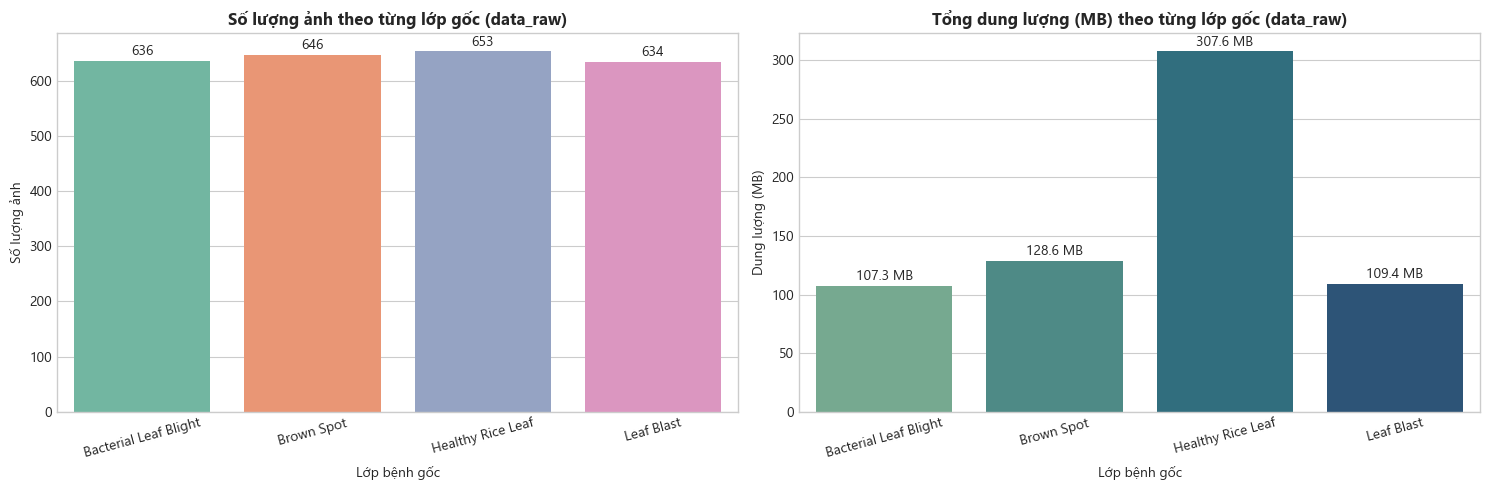

In [12]:
# Sơ đồ trực quan hóa dữ liệu thô (data_raw)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Số lượng mẫu từng lớp
sns.barplot(data=raw_summary, x='Lớp gốc', y='Số lượng (ảnh)', palette='Set2', ax=axes[0])
axes[0].set_title('Số lượng ảnh theo từng lớp gốc (data_raw)', fontsize=12, weight='bold')
axes[0].set_xlabel('Lớp bệnh gốc', fontsize=10)
axes[0].set_ylabel('Số lượng ảnh', fontsize=10)
axes[0].tick_params(axis='x', rotation=15)
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())}",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

# 2. Dung lượng MB từng lớp
sns.barplot(data=raw_summary, x='Lớp gốc', y='Dung lượng (MB)', palette='crest', ax=axes[1])
axes[1].set_title('Tổng dung lượng (MB) theo từng lớp gốc (data_raw)', fontsize=12, weight='bold')
axes[1].set_xlabel('Lớp bệnh gốc', fontsize=10)
axes[1].set_ylabel('Dung lượng (MB)', fontsize=10)
axes[1].tick_params(axis='x', rotation=15)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f} MB",
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()

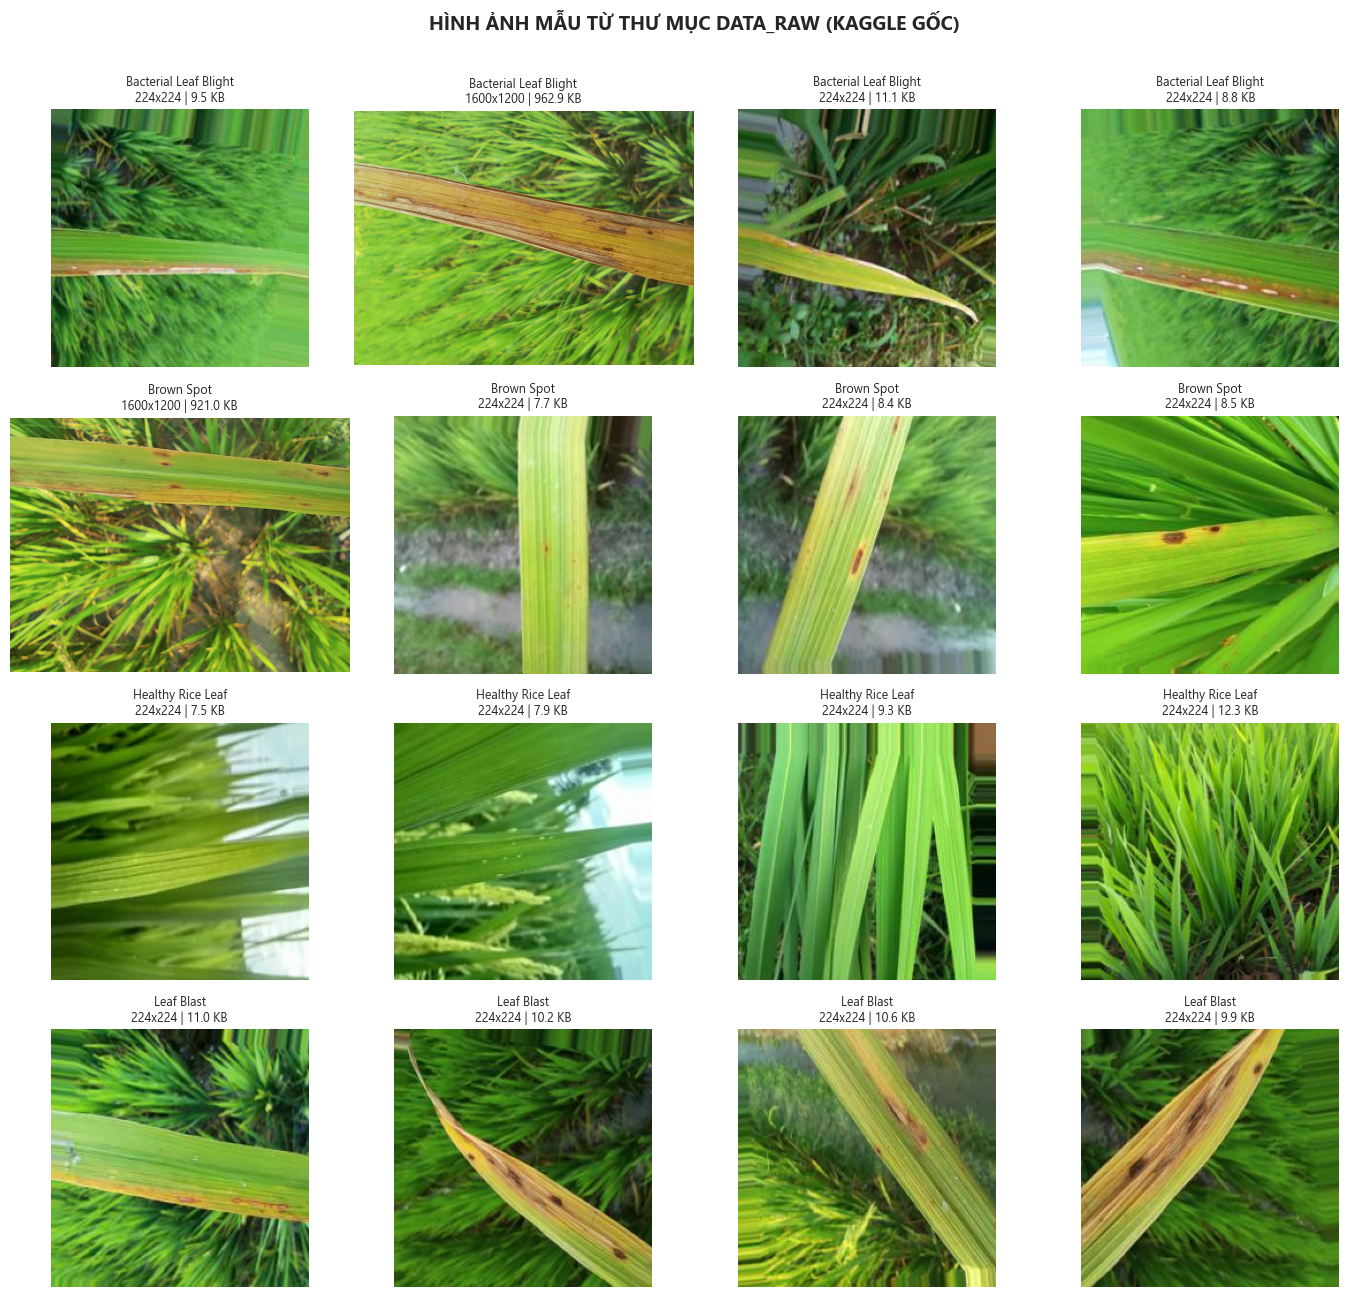

In [13]:
# Trực quan hóa ảnh mẫu của 4 lớp trong data_raw
raw_classes = sorted(df_raw['Lớp gốc'].unique())
fig, axes = plt.subplots(len(raw_classes), 4, figsize=(14, 3.2 * len(raw_classes)))

for r_idx, cls in enumerate(raw_classes):
    sub = df_raw[df_raw['Lớp gốc'] == cls].sample(4, random_state=42)
    for c_idx, (_, row) in enumerate(sub.iterrows()):
        ax = axes[r_idx, c_idx]
        img = Image.open(row['Đường dẫn'])
        ax.imshow(img)
        ax.axis('off')
        ax.set_title(f"{cls}\n{img.size[0]}x{img.size[1]} | {row['Dung lượng (KB)']:.1f} KB", fontsize=9)

plt.suptitle('HÌNH ẢNH MẪU TỪ THƯ MỤC DATA_RAW (KAGGLE GỐC)', fontsize=14, weight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## 2. Khám Phá Dữ Liệu Đã Xử Lý (data_processed)

- **Quy trình xử lý**: Dữ liệu đã được gán nhãn và xử lý thông qua công cụ **Roboflow**:
  - Chuẩn hóa tên tệp theo định dạng: `<mã_lớp>_<số_thứ_tự>.jpg`.
  - Tự động phân chia thành 3 tập phục vụ học máy: `train`, `valid`, `test`.
  - Kèm theo tệp chú thích `labels.csv` lưu trữ đường dẫn ảnh, nhãn, tập phân chia và tên tệp gốc.
- **Bảng ánh xạ nhãn (Label Mapping)**:
  - `Bacterial Leaf Blight` $\rightarrow$ `bac_la` (Bạc lá lúa)
  - `Leaf Blast` $\rightarrow$ `dao_on` (Đạo ôn lá)
  - `Brown Spot` $\rightarrow$ `dom_nau` (Đốm nâu)
  - `Healthy Rice Leaf` $\rightarrow$ `la_khoe` (Lá khỏe mạnh)

In [14]:
# Đọc tệp labels.csv từ Roboflow và kiểm tra thông tin
labels_csv_path = PROCESSED_DIR / 'labels.csv'
df_labels = pd.read_csv(labels_csv_path)

label_mapping = {
    'bac_la': 'Bạc lá lúa',
    'dao_on': 'Đạo ôn lá',
    'dom_nau': 'Đốm nâu',
    'la_khoe': 'Lá khỏe mạnh'
}
df_labels['Tên tiếng Việt'] = df_labels['label'].map(label_mapping)

print(f"Tổng số mẫu được ghi nhận trong labels.csv: {len(df_labels):,} bản ghi")
print("\n5 dòng đầu tiên trong tệp labels.csv:")
df_labels[['image_path', 'label', 'Tên tiếng Việt', 'split', 'original_filename']].head()

Tổng số mẫu được ghi nhận trong labels.csv: 2,485 bản ghi

5 dòng đầu tiên trong tệp labels.csv:


,image_path,label,Tên tiếng Việt,split,original_filename
0,train/bac_la_0001.jpg,bac_la,Bạc lá lúa,train,20231006_164208_jpg.rf.283e7c405bbf3da17ed6358...
1,train/bac_la_0002.jpg,bac_la,Bạc lá lúa,train,aug_0_1018_jpg.rf.f1ba48253503379003a4e5e01f1a...
2,train/bac_la_0003.jpg,bac_la,Bạc lá lúa,train,aug_0_1031_jpg.rf.9751c284557f4167407ddfa2a750...
3,train/bac_la_0004.jpg,bac_la,Bạc lá lúa,train,aug_0_1036_jpg.rf.11ff195583138a971625e92f32b3...
4,train/bac_la_0005.jpg,bac_la,Bạc lá lúa,train,aug_0_1047_jpg.rf.49bc5266a87b362c76416be8582e...


In [15]:
# Bảng thống kê phân bố data_processed theo tập và lớp bệnh
summary_proc = df_labels.groupby(['split', 'Tên tiếng Việt']).size().unstack(fill_value=0)
summary_proc = summary_proc.reindex(['train', 'valid', 'test'])

summary_proc['Tổng số'] = summary_proc.sum(axis=1)
summary_proc.loc['Tổng cộng'] = summary_proc.sum(axis=0)
summary_proc['Tỷ lệ (%)'] = (summary_proc['Tổng số'] / summary_proc.loc['Tổng cộng', 'Tổng số'] * 100).round(2)

print("BẢNG PHÂN BỐ DỮ LIỆU DATA_PROCESSED (ROBOFLOW SPLIT):")
summary_proc

BẢNG PHÂN BỐ DỮ LIỆU DATA_PROCESSED (ROBOFLOW SPLIT):


Tên tiếng Việt,Bạc lá lúa,Lá khỏe mạnh,Đạo ôn lá,Đốm nâu,Tổng số,Tỷ lệ (%)
split,,,,,,
train,428,430,433,449,1740,70.02
valid,122,123,124,127,496,19.96
test,62,61,62,64,249,10.02
Tổng cộng,612,614,619,640,2485,100.00


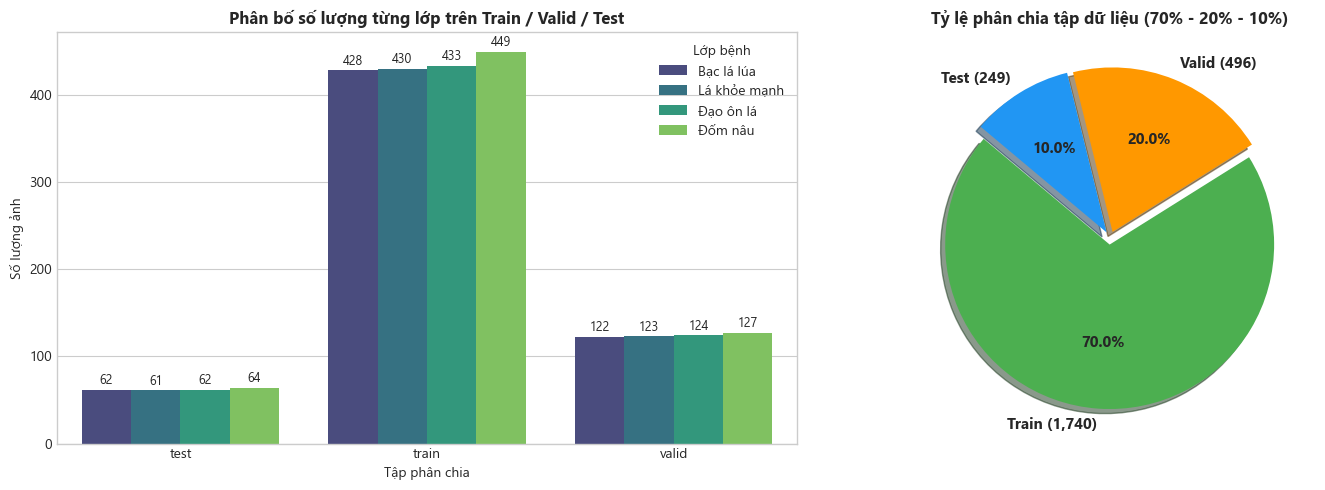

In [16]:
# Sơ đồ phân bố dữ liệu data_processed
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Số lượng từng lớp theo tập phân chia
split_counts = df_labels.groupby(['split', 'Tên tiếng Việt']).size().reset_index(name='Số lượng')
sns.barplot(data=split_counts, x='split', y='Số lượng', hue='Tên tiếng Việt', palette='viridis', ax=axes[0])
axes[0].set_title('Phân bố số lượng từng lớp trên Train / Valid / Test', fontsize=12, weight='bold')
axes[0].set_xlabel('Tập phân chia', fontsize=10)
axes[0].set_ylabel('Số lượng ảnh', fontsize=10)
axes[0].legend(title='Lớp bệnh')
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{int(h)}",
                         (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# 2. Tỷ lệ phân chia Train - Valid - Test
split_totals = df_labels['split'].value_counts()[['train', 'valid', 'test']]
axes[1].pie(
    split_totals,
    labels=[f"Train ({split_totals['train']:,})", f"Valid ({split_totals['valid']:,})", f"Test ({split_totals['test']:,})"],
    autopct='%1.1f%%',
    startangle=140,
    colors=['#4CAF50', '#FF9800', '#2196F3'],
    explode=(0.04, 0.04, 0.04),
    shadow=True,
    textprops={'fontsize': 11, 'weight': 'bold'}
)
axes[1].set_title('Tỷ lệ phân chia tập dữ liệu (70% - 20% - 10%)', fontsize=12, weight='bold')

plt.tight_layout()
plt.show()

---
## 3. So Sánh Trực Quan: data_raw vs data_processed

Đánh giá sự thay đổi giữa dữ liệu thô ban đầu và dữ liệu sau khi qua tiền xử lý / gắn nhãn Roboflow.

In [17]:
# Bảng so sánh giữa data_raw và data_processed
raw_to_proc_class = {
    'Bacterial Leaf Blight': 'bac_la',
    'Brown Spot': 'dom_nau',
    'Healthy Rice Leaf': 'la_khoe',
    'Leaf Blast': 'dao_on'
}

raw_class_counts = df_raw['Lớp gốc'].map(raw_to_proc_class).value_counts().to_dict()
proc_class_counts = df_labels['label'].value_counts().to_dict()

comp_records = []
for p_cls, vi_name in label_mapping.items():
    n_raw = raw_class_counts.get(p_cls, 0)
    n_proc = proc_class_counts.get(p_cls, 0)
    comp_records.append({
        'Mã lớp': p_cls,
        'Tên bệnh': vi_name,
        'data_raw (ảnh)': n_raw,
        'data_processed (ảnh)': n_proc,
        'Chênh lệch (ảnh)': n_proc - n_raw
    })

df_comp = pd.DataFrame(comp_records)

# Tính tổng dung lượng
total_raw_mb = round(df_raw['Dung lượng (KB)'].sum() / 1024, 2)
proc_files_sz = sum((PROCESSED_DIR / row['image_path']).stat().st_size for _, row in df_labels.iterrows())
total_proc_mb = round(proc_files_sz / (1024 ** 2), 2)

print(f"Tổng số ảnh: data_raw = {len(df_raw):,} ảnh | data_processed = {len(df_labels):,} ảnh (Giảm {len(df_raw) - len(df_labels)} ảnh do Roboflow lọc bỏ ảnh lỗi hoặc trùng lặp)")
print(f"Dung lượng : data_raw = {total_raw_mb:.2f} MB | data_processed = {total_proc_mb:.2f} MB (Tiết kiệm {(1 - total_proc_mb/total_raw_mb)*100:.1f}% dung lượng nhờ tối ưu độ phân giải)")
print("\nBẢNG SO SÁNH SỐ LƯỢNG ẢNH TỪNG LỚP:")
df_comp

Tổng số ảnh: data_raw = 2,569 ảnh | data_processed = 2,485 ảnh (Giảm 84 ảnh do Roboflow lọc bỏ ảnh lỗi hoặc trùng lặp)
Dung lượng : data_raw = 652.87 MB | data_processed = 90.38 MB (Tiết kiệm 86.2% dung lượng nhờ tối ưu độ phân giải)

BẢNG SO SÁNH SỐ LƯỢNG ẢNH TỪNG LỚP:


,Mã lớp,Tên bệnh,data_raw (ảnh),data_processed (ảnh),Chênh lệch (ảnh)
0,bac_la,Bạc lá lúa,636,612,-24
1,dao_on,Đạo ôn lá,634,619,-15
2,dom_nau,Đốm nâu,646,640,-6
3,la_khoe,Lá khỏe mạnh,653,614,-39


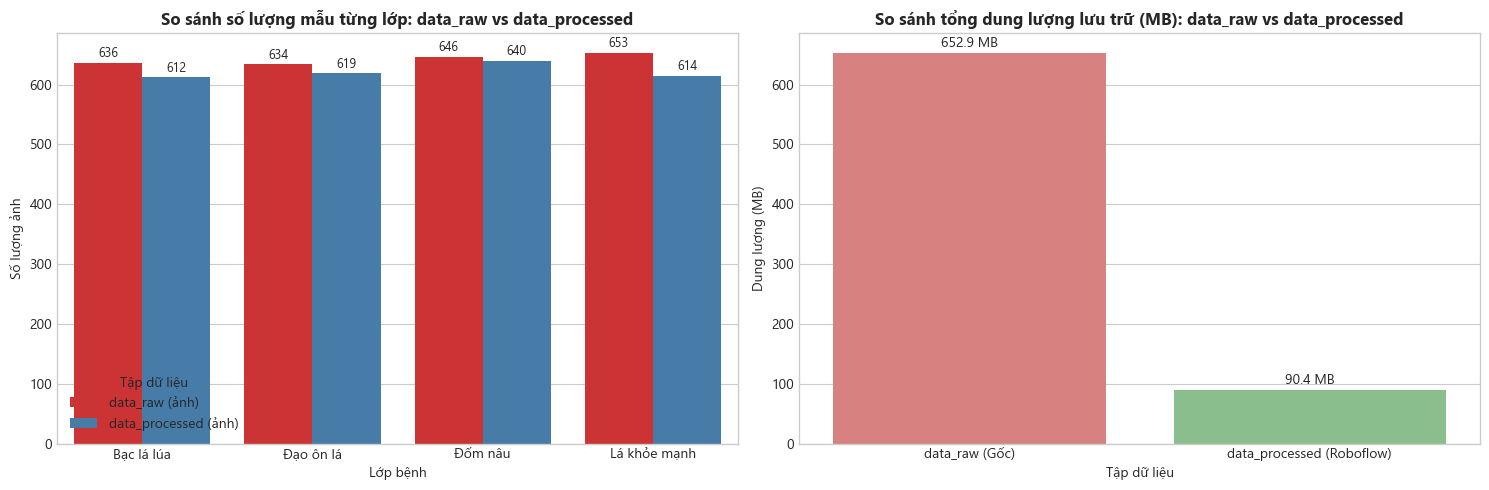

In [18]:
# Sơ đồ so sánh trực quan data_raw vs data_processed
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. So sánh số lượng mẫu từng lớp
df_comp_melt = df_comp.melt(id_vars=['Tên bệnh'], value_vars=['data_raw (ảnh)', 'data_processed (ảnh)'], var_name='Tập dữ liệu', value_name='Số lượng')
sns.barplot(data=df_comp_melt, x='Tên bệnh', y='Số lượng', hue='Tập dữ liệu', palette='Set1', ax=axes[0])
axes[0].set_title('So sánh số lượng mẫu từng lớp: data_raw vs data_processed', fontsize=12, weight='bold')
axes[0].set_xlabel('Lớp bệnh', fontsize=10)
axes[0].set_ylabel('Số lượng ảnh', fontsize=10)
for p in axes[0].patches:
    h = p.get_height()
    if h > 0:
        axes[0].annotate(f"{int(h)}",
                         (p.get_x() + p.get_width() / 2., h),
                         ha='center', va='bottom', fontsize=9, xytext=(0, 2), textcoords='offset points')

# 2. So sánh tổng dung lượng lưu trữ (MB)
df_size_comp = pd.DataFrame({
    'Tập dữ liệu': ['data_raw (Gốc)', 'data_processed (Roboflow)'],
    'Dung lượng (MB)': [total_raw_mb, total_proc_mb]
})
sns.barplot(data=df_size_comp, x='Tập dữ liệu', y='Dung lượng (MB)', palette=['#E57373', '#81C784'], ax=axes[1])
axes[1].set_title('So sánh tổng dung lượng lưu trữ (MB): data_raw vs data_processed', fontsize=12, weight='bold')
axes[1].set_xlabel('Tập dữ liệu', fontsize=10)
axes[1].set_ylabel('Dung lượng (MB)', fontsize=10)
for p in axes[1].patches:
    h = p.get_height()
    axes[1].annotate(f"{h:.1f} MB",
                     (p.get_x() + p.get_width() / 2., h),
                     ha='center', va='bottom', fontsize=10, xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
plt.show()

---
## 4. Kết Luận và Định Hướng Huấn Luyện CNN

- **Dữ liệu thô (data_raw)**: Cung cấp đầy đủ 2,569 ảnh gốc từ Kaggle, độ phân giải cao nhưng dung lượng lớn (652.87 MB) và chưa được phân chia thành các tập huấn luyện/thẩm định/kiểm thử.
- **Dữ liệu đã xử lý (data_processed)**:
  - Đã được lọc bỏ 84 ảnh không hợp lệ, giữ lại 2,485 ảnh đồng nhất về chất lượng.
  - Dung lượng giảm từ 652.87 MB xuống 90.38 MB (tiết kiệm ~86% bộ nhớ), giúp tối ưu hóa dung lượng RAM và tăng tốc độ đọc dữ liệu (I/O) khi huấn luyện.
  - Phân chia sẵn theo tỷ lệ chuẩn: 70% Train (1,740 ảnh), 20% Valid (496 ảnh), 10% Test (249 ảnh).
  - Phân bố giữa 4 lớp bệnh hoàn toàn cân bằng (~25% mỗi lớp), sẵn sàng đưa vào các mô hình CNN tiếp theo.